In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
np.random.seed(42)
plt.style.use('fivethirtyeight')
sns.set()
sns.set_context("talk")
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 9)

# Regression

In [5]:
# create random X and Y
X = np.random.normal(70, 1, size=(50, 1))
Y = np.random.normal(70, 1, size=(50, 1))
X

array([[70.49671415],
       [69.8617357 ],
       [70.64768854],
       [71.52302986],
       [69.76584663],
       [69.76586304],
       [71.57921282],
       [70.76743473],
       [69.53052561],
       [70.54256004],
       [69.53658231],
       [69.53427025],
       [70.24196227],
       [68.08671976],
       [68.27508217],
       [69.43771247],
       [68.98716888],
       [70.31424733],
       [69.09197592],
       [68.5876963 ],
       [71.46564877],
       [69.7742237 ],
       [70.0675282 ],
       [68.57525181],
       [69.45561728],
       [70.11092259],
       [68.84900642],
       [70.37569802],
       [69.39936131],
       [69.70830625],
       [69.39829339],
       [71.85227818],
       [69.98650278],
       [68.94228907],
       [70.82254491],
       [68.77915635],
       [70.2088636 ],
       [68.04032988],
       [68.67181395],
       [70.19686124],
       [70.73846658],
       [70.17136828],
       [69.88435172],
       [69.6988963 ],
       [68.52147801],
       [69

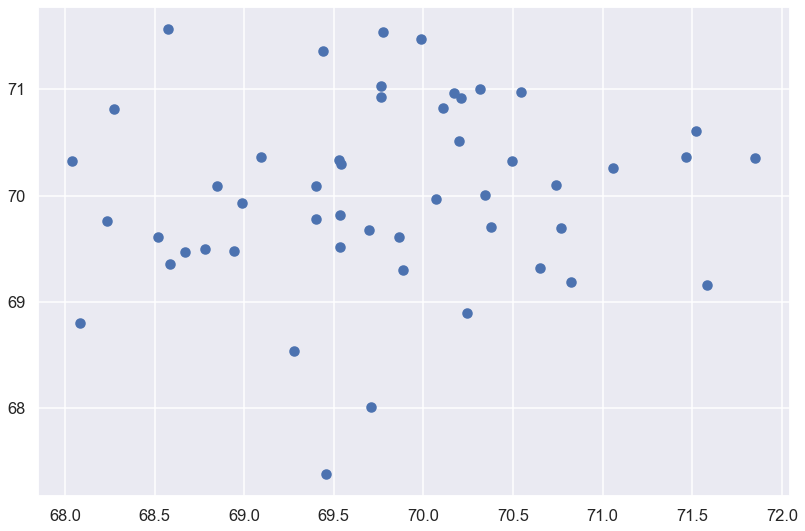

In [7]:
# view the scaled data
plt.scatter(X, Y)

In [6]:
# normalize data using MinMaxScaler from sklearn.preprocessing
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_trans = scaler.fit_transform(X)
y_trans = scaler.fit_transform(Y)
x_trans


array([[0.64439076],
       [0.47781493],
       [0.68399633],
       [0.91362728],
       [0.45266006],
       [0.45266437],
       [0.92836593],
       [0.71540972],
       [0.39092758],
       [0.65641765],
       [0.39251645],
       [0.39190992],
       [0.57756093],
       [0.0121696 ],
       [0.06158328],
       [0.36657963],
       [0.24838716],
       [0.59652369],
       [0.27588151],
       [0.1435923 ],
       [0.89857433],
       [0.45485764],
       [0.53180111],
       [0.1403277 ],
       [0.37127665],
       [0.54318489],
       [0.21214258],
       [0.61264423],
       [0.35651885],
       [0.43756532],
       [0.3562387 ],
       [1.        ],
       [0.51054546],
       [0.2366137 ],
       [0.72986694],
       [0.1938186 ],
       [0.56887805],
       [0.        ],
       [0.16565914],
       [0.56572943],
       [0.70781041],
       [0.55904179],
       [0.48374786],
       [0.43509678],
       [0.12622105],
       [0.32524731],
       [0.39324546],
       [0.791

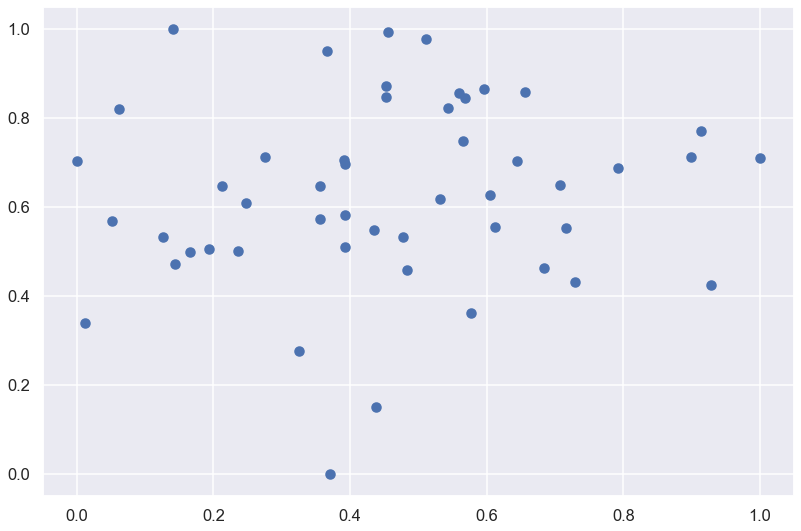

In [8]:
# view the scaled data
plt.scatter(x_trans, y_trans)

$$
h(\theta) = \theta_0 + \theta_1*x 
$$

In [10]:
# define the function h(theta)
def h(theta0, theta1, x):
    """
    Return the model theta0 + theta1*x
    
    """
    return theta0 + theta1*x

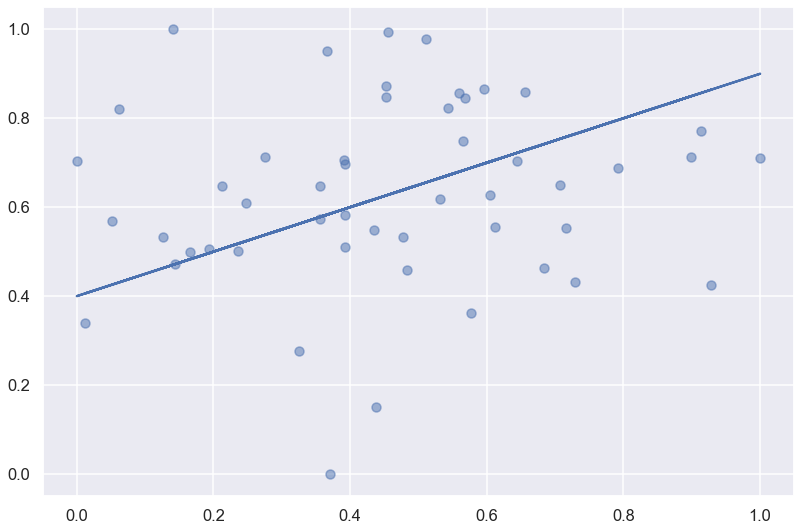

In [11]:
# view data and regression line for theta0=0.4, theta1=0.5
import pylab
y_pred = h(0.4, 0.5, x_trans)
pylab.plot(x_trans, y_pred)
pylab.scatter(x_trans, y_trans, alpha=0.5)

$$
E(\theta) = \sum(h(\theta)-y)^2   $$

In [12]:
# calculate the square loss

def sqerror(x, y, theta0, theta1):
    """
    Input: parameters theta0 and theta1 of the model
    Input: x, y vectors
    Returns: L2 square error
    Assumptions: none
    """
    L = lambda a: a ** 2
    y_pred = h(theta0, theta1, x)
    err_lst = y - y_pred
    return float(sum(L(err_lst)) / len(x))

In [13]:
sqerror(x_trans, y_trans, 0.4, 0.5)

0.05197211539301634

# Gradient Descent

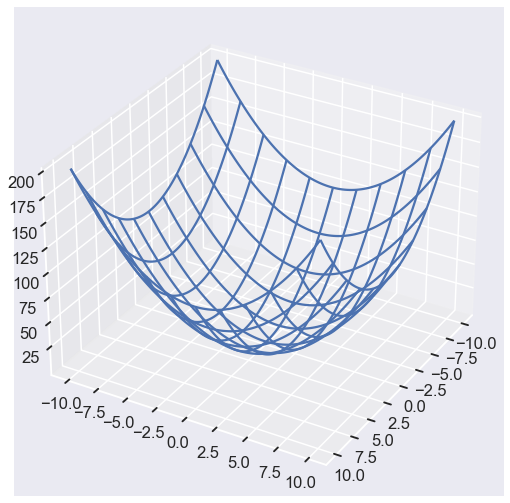

In [14]:
from mpl_toolkits.mplot3d import axes3d

u = np.linspace(-10, 10, 100)
[x,y] = np.meshgrid(u, u)
squared = np.sqrt(x.flatten()**2 + y.flatten()**2)
z = squared**2
z = z.reshape(x.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_wireframe(x, y, z, rstride=10, cstride=10)
ax.view_init(elev=30., azim=30)
plt.savefig("figure1.png")

$$
\theta_0 = \theta_0 - \alpha*\frac{d sqerror}{d \theta_0}
$$

$$
\theta_1 = \theta_1 - \alpha*\frac{d sqerror}{d \theta_1}
$$

### <center>Take the original formula:<center>

$$
sqerror = \sum(\theta_1*x_j + \theta_0-y_j)^2
$$

### <center>Take the derivatives:<center>

$$
\frac{d sqerror}{d \theta_0} = \sum(2*(\theta_1*x_j + \theta_0-y_j))
$$

$$
\frac{d sqerror}{d \theta_1} = \sum(2*(\theta_1*x_j + \theta_0-y_j)*x_j)
$$

### <center>Now we have something to substitute into the gradient descent formulas:<center>

$$
\theta_0 = \theta_0 - \alpha*\frac{d sqerror}{d \theta_0}
$$

$$
\theta_1 = \theta_1 - \alpha*\frac{d sqerror}{d \theta_1}
$$

### <center>Resulting in:<center>

$$
\theta_0 = \theta_0 - \alpha*\sum((\theta_1*x_j + \theta_0)-y_j)
$$

$$
\theta_1 = \theta_1 - \alpha*\sum((\theta_1*x_j + \theta_0 - y_j)*x_j)
$$

<center>(Note that the factor of 2 is absorbed by the user-set constant alpha)<center>

In [15]:
# Gradient descent
# Given the observed data(x, y), and initial theta0 and theta1, using the formula above to 
# update theta at each iteration, stop until abs(newError - oldError) is less than the threshold
# In this example, the threshold is set as 0.00001 and learning rate(alpha) is set as 0.01

sum_theta0 = lambda a,b : float(sum(b*x+a-y for x,y in zip(x_trans, y_trans)))
sum_theta1 = lambda a,b : float(sum((b*x+a-y)*x for x,y in zip(x_trans, y_trans)))

prev_theta0, prev_theta1 = 0, 0
oldError = sqerror(x_trans, y_trans, prev_theta0, prev_theta1)
newError = oldError + 100
iterations = 0

print(f'iter_num = {iterations}, theta0 = {prev_theta0}, theta1 = {prev_theta1}')

while abs(newError - oldError) >= 0.00001:
    theta0 = prev_theta0 - 0.01*sum_theta0(prev_theta0, prev_theta1)
    theta1 = prev_theta1 - 0.01*sum_theta1(prev_theta0, prev_theta1)
    
    newError = sqerror(x_trans, y_trans, theta0, theta1)
    oldError = sqerror(x_trans, y_trans, prev_theta0, prev_theta1)

    prev_theta0 = theta0
    prev_theta1 = theta1
    
    iterations += 1
    print(f'iter_num = {iterations}, theta0 = {theta0}, theta1 = {theta1}, newError = {newError}')

print()
print(f'theta0: {theta0}, theta1: {theta1}')
print("new error:",newError)
print("number of iterations:", iterations)

iter_num = 0, theta0 = 0, theta1 = 0
iter_num = 1, theta0 = 0.3151626349625274, theta1 = 0.14613945056939237, newError = 0.10426958691069517
iter_num = 2, theta0 = 0.4395018329203626, theta1 = 0.2011703541730504, newError = 0.052805914483190115
iter_num = 3, theta0 = 0.4891536355893343, theta1 = 0.22060551373724782, newError = 0.04487751230068076
iter_num = 4, theta0 = 0.5095586506082309, theta1 = 0.22616391299596536, newError = 0.04361624322636321
iter_num = 5, theta0 = 0.5184967974553303, theta1 = 0.22634221545603994, newError = 0.043377903161333414
iter_num = 6, theta0 = 0.5229253126882886, theta1 = 0.22446367839413886, newError = 0.04329832079363234
iter_num = 7, theta0 = 0.5255668782855873, theta1 = 0.22182741329029945, newError = 0.04324509837196008
iter_num = 8, theta0 = 0.5274873283153357, theta1 = 0.21894058161598048, newError = 0.043197869229309065
iter_num = 9, theta0 = 0.5291042165596653, theta1 = 0.21600050967085407, newError = 0.043153422056884244
iter_num = 10, theta0 = 

In [ ]:
y_pred_new = h(theta0, theta1, x_trans)
#remember, y_pred = h(0.4, 0.5, x_trans)
pylab.plot(x_trans, y_pred)
pylab.plot(x_trans, y_pred_new)
pylab.scatter(x_trans, y_trans, alpha=0.5)